<a href="https://colab.research.google.com/github/Shunsuke-max/vamp721-structural-ensemble/blob/main/VAMP721_PICALM1a_BioEmu2_Complex_Equilibrium_%E5%AD%A6%E7%BF%92%E7%89%88_v2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# VAMP721–PICALM1a複合体の構造アンサンブルを探索する
### BioEmu-2 Sample Equilibrium｜研究・学習ノートブック v2.0

**研究上の問い**：PICALM1aが存在するとき、VAMP721のSNARE領域の二次構造、Longin–SNARE接触、PICALM1aとの界面にどのような*予測上の違い*が現れるか？

**初期条件**：VAMP721 WT **1–185 aa** + PICALM1a **31–309 aa**（合計464残基）、`mode="equilibrium"`、8構造、seed 42、接触拘束なし。

**このノートブックの到達目標**
1. BioEmu-2の構造生成、MSA、equilibrium/structureの違いを説明できる。
2. 入力コンストラクトを検証し、複合体構造を生成して幾何品質を点検できる。
3. DSSPによるヘリックス率と鎖間・鎖内接触の分布を再現可能な方法で算出できる。
4. **文献の事実／AIの出力／仮説**を区別して解釈できる。

> **重要**：生成フレームは時間軌跡ではなく独立した配座候補です。生成頻度から生体内の平衡存在比・結合親和性・結合経路・自由エネルギーを直接決定できません。実験SAXS（従来Open 57%/Closed 43%）は**VAMP721単独**であり、本複合体のSAXS適合度をこのノートブックは評価しません。

**使い方**：Google Colabで開き、`ランタイム → ランタイムのタイプを変更 → GPU`を選択。上から順に実行。最初の実行はMSA探索・重みの取得でネット接続が必要です。長い系ではGPUメモリが不足し得るため、初回8構造でも完走を保証できません。

## 0｜根拠・仮説・評価の区別

- **既存研究（文献・実験）**：植物PICALM1a/1bはVAMP72群の回収に関与し、SNARE領域との相互作用が報告されている（Fujimoto et al., *PNAS*, 2020）。
- **実施済みAI解析**：VAMP721 1–185のBioEmu-2では、136–185残基のDSSP `H`率がEquilibrium100構造で**9.1%**、Structure32構造で**40.5%**。両モードは条件付けとsharpeningも異なり、この差を生体のヘリックス率と解釈できない。
- **検証する仮説**：PICALM1aとの複合体では、単独と異なるSNAREのヘリックス分布やLongin–SNARE接触分布が得られるかもしれない。
- **未確認**：PICALM1a 31–309という断片が実際の溶液中でVAMP721に十分結合すること、今回の複合体構造、結合経路、SAXS試料との配列の一致。

本ノートブックは**構造候補の探索**です。結合の有無や相互作用の機構を実証するにはSPR、CD、FRET、HS-AFM、複合体SAXSなど独立実験が必要です。

**公式資料**：[BioEmu-2](https://github.com/microsoft/bioemu2) / [Sampling](https://github.com/microsoft/bioemu2/blob/main/docs/sampling.md) / [MSA](https://github.com/microsoft/bioemu2/blob/main/docs/msa.md) / [System](https://github.com/microsoft/bioemu2/blob/main/docs/system.md)

**実行前の問い**：もしPICALM1aがSNAREのヘリックス構造を安定化するとしたら、どの量を単独タンパク質と比較すれば反証可能だろうか？

## 1｜BioEmu-2の何を学ぶか

BioEmu-2は拡散モデルを利用し、条件付けされたタンパク質の原子座標候補を生成します。概念的には、ノイズから構造を段階的に形成する逆拡散に相当します。ただし、**各逆拡散ステップは物理的な時間経過ではありません**。

| APIのモード | 対応CLI | 目標 | 公式の標準step_scale |
|---|---|---|---:|
| `equilibrium` | `sample-equilibrium` | モデル化された配座アンサンブルの探索 | 1.0（sharpeningなし） |
| `structure` | `predict-structure` | 精度の高い個別構造予測 | 1.5（sharpeningあり） |

**注意**：2モードは出力の「最安定構造 vs 真のBoltzmann分布」という単純な関係ではありません。タスク条件とサンプラー設定が異なり、予測頻度に直接的な熱力学的意味を与えないこと。

複合体では、**A鎖とB鎖を別々のProteinとしてSystemに入力**します。構造モデルが界面を生成しても、それが実際に結合する保証はありません。以下では接触を*事前指定しない*条件を採用します。

## 2｜実験計画・設定を最初の1か所に集める

**最重要セル**です。このセルを変えると実験IDや保存先も更新されます。まずは初期設定のまま動作確認してください。

- `VAMP_CONSTRUCT="WT_1_185"` は既存VAMP721単独Equilibrium100と配列が一致する。
- `AF3_194` は以前のAF3入力に対応する比較候補であり、参照WTとは193残基以降が異なる。
- `PICALM_CONSTRUCT="ANTH_31_309"` は計算負荷を抑える探索用の断片。単独結合能は未確認。
- `RUN_TAG`を変えると新しい実行ディレクトリになる。中断時はすべての設定を同じまま再実行する。

**予想を書こう**：単独の9.1%に対して複合体H率は上がる／下がる／変わらないのどれを予想するか？ そう考える理由は何か？

In [ ]:
# ===== 設定セル：このセルで入力条件を一括管理 =====
VAMP_CONSTRUCT = "WT_1_185"      # "WT_1_185" or "AF3_194"
PICALM_CONSTRUCT = "ANTH_31_309" # "ANTH_31_309", "NTERM_1_309", "FULL_1_571"
MODE = "equilibrium"             # "equilibrium" or "structure"
N_SAMPLES = 8                    # 初回は8。動作後16, 50, 100等
RANDOM_SEED = 42
BATCH_SIZE = 1                   # GPUが許す範囲で増やせる
CONTACT_CUTOFF_A = 8.0          # Cα原子間の距離（Å）
RUN_TAG = "trial01"              # 別の実行では変更。中断復旧時は同じ値
FETCH_MSA_EXPLICITLY = True     # MSAを表示・記録する。FalseならEmuSessionが取得
RUN_OPTIONAL_SASA = False       # 重い解析。必要な場合にTrue。別の実行ではRUN_TAGも変更
AUTO_DOWNLOAD_ZIP = False       # ColabでZIPのダウンロードを開始するならTrue

assert MODE in ("equilibrium", "structure")
assert VAMP_CONSTRUCT in ("WT_1_185", "AF3_194")
assert PICALM_CONSTRUCT in ("ANTH_31_309", "NTERM_1_309", "FULL_1_571")
assert N_SAMPLES > 0 and BATCH_SIZE > 0 and RANDOM_SEED >= 0
assert CONTACT_CUTOFF_A > 0
import re
assert re.fullmatch(r"[A-Za-z0-9_-]+", RUN_TAG), "RUN_TAGは英数字/ハイフン/アンダーバーにしてください"
print("MODE:", MODE, "/ N:", N_SAMPLES, "/ seed:", RANDOM_SEED)

MODE: equilibrium / N: 8 / seed: 42


## 3｜Colab環境の確認と必要時のみセットアップ

GPU利用の有無、Pythonの版、GPU名と総VRAMを表示します。**464残基の複合体**は小さい単量体より大幅に重くなる可能性があります。VRAM不足が生じた場合、`BATCH_SIZE=1`でも改善しないケースがあり、その場合はGPUの変更や短い構築体の検討が必要です。

**学習の視点**：GPUが必要になるのはなぜか？ タンパク質の長さが増えると、内部で保持する特徴量や注意機構の計算量はどのように変わるか？

In [ ]:
import sys, subprocess, importlib.util
print("Python:", sys.version.split()[0])
print("bioemu2 installed:", importlib.util.find_spec("bioemu2") is not None)
proc = subprocess.run(["nvidia-smi"], text=True, capture_output=True)
print(proc.stdout[:1800] if proc.returncode == 0 else "nvidia-smiが利用できません。GPUランタイムを確認してください。")

Python: 3.13.16
bioemu2 installed: True
Tue Nov 10 01:46:09 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  NVIDIA A100-SXM4-40GB          Off |   00000000:00:04.0 Off |                    0 |
| N/A   35C    P0             45W /  400W |       0MiB /  40960MiB |      0%      Default |
|                                         |                        |             Disabled |
+-------

### 3.1｜BioEmu-2の導入（未導入の場合だけ実行）

元ノートブックのGitHubインストール方式を引き継ぎます。Google Colabの環境やBioEmu-2の依存関係は更新される場合があります。実行失敗時は[公式README](https://github.com/microsoft/bioemu2)の導入手順を優先してください。導入後にランタイム再起動が必要なら、冒頭から実行し直します。

In [ ]:
import importlib.util, sys, subprocess
from pathlib import Path
if importlib.util.find_spec("bioemu2") is None:
    if sys.version_info < (3, 12):
        raise RuntimeError("BioEmu-2の現行環境にはPython 3.12以降が推奨されます。ColabのPython環境を確認してください。")
    repo = Path("/content/bioemu2_source")
    if not repo.exists():
        subprocess.check_call(["git", "clone", "--depth", "1", "https://github.com/microsoft/bioemu2.git", str(repo)])
    cap_proc = subprocess.run(
        ["nvidia-smi", "--query-gpu=compute_cap", "--format=csv,noheader"],
        capture_output=True, text=True
    )
    cc = cap_proc.stdout.strip().splitlines()[0] if cap_proc.returncode==0 and cap_proc.stdout.strip() else ""
    if cc == "7.0":  # V100: CUDA 12.6版が必要（公式README）
        cmd = [sys.executable, "-m", "pip", "install", "-q", f"{repo}[cuda12,viz]",
               "--extra-index-url", "https://download.pytorch.org/whl/cu126"]
    else:
        cmd = [sys.executable, "-m", "pip", "install", "-q", f"{repo}[cuda,viz]"]
    print("Compute capability:", cc or "unknown", "| Installing:", "cuda12" if cc=="7.0" else "cuda")
    subprocess.check_call(cmd)
if importlib.util.find_spec("py3Dmol") is None:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "py3Dmol"])
print("ライブラリの導入確認が終わりました。")

ライブラリの導入確認が終わりました。


In [ ]:
import torch, importlib.metadata
assert torch.cuda.is_available(), "CUDA GPUが見つかりません。ColabのGPUランタイムに切り替えてください。"
prop = torch.cuda.get_device_properties(0)
print("GPU:", torch.cuda.get_device_name(0))
print("VRAM (GiB):", round(prop.total_memory/1024**3, 1))
print("torch:", torch.__version__)
print("bioemu2:", importlib.metadata.version("bioemu2"))
print("※ 表示されたVRAMが十分でもOOMの可能性は残ります。")

GPU: NVIDIA A100-SXM4-40GB
VRAM (GiB): 39.5
torch: 2.13.0+cu130
bioemu2: 0.1.0rc0
※ 表示されたVRAMが十分でもOOMの可能性は残ります。


## 4｜配列を検証する：185 aa / 194 aaはどこが違うか

単独解析で使ったVAMP721 canonical 219 aa（UniProt Q9ZTW3）の配列と、ユーザー提供のAF3複合体用194 aaを**独立した配列として保持**します。

- 両者は**1–192番まで一致**。WTの193–194番は`KI`、AF3用194 aaの193–194番は`VD`。
- 1–185残基で比較する場合には両者の先頭185残基が一致する。
- 194 aaはcanonical WTの194残基切断体ではなく、末端が異なることに留意する。

PICALM1aは571 aaの全長配列を保持し、31–309を使うときはPythonのスライス `[30:309]` を用います。**B鎖の構造内番号は1–279**、天然配列上の元番号は31–309です。

In [ ]:
# 配列は既存の「VAMP721単独学習ノートブック」「複合体ノートブック」から転記
VAMP721_CANONICAL_219 = 'MAQQSLIYSFVARGTVILVEFTDFKGNFTSIAAQCLQKLPSSNNKFTYNCDGHTFNYLVEDGFTYCVVAVDSAGRQIPMSFLERVKEDFNKRYGGGKAATAQANSLNKEFGSKLKEHMQYCMDHPDEISKLAKVKAQVSEVKGVMMENIEKVLDRGEKIELLVDKTENLRSQAQDFRTTGTQMRRKMWLQNMKIKLIVLAIIIALILIIVLSVCHGFKC'
VAMP721_AF3_194 = 'MAQQSLIYSFVARGTVILVEFTDFKGNFTSIAAQCLQKLPSSNNKFTYNCDGHTFNYLVEDGFTYCVVAVDSAGRQIPMSFLERVKEDFNKRYGGGKAATAQANSLNKEFGSKLKEHMQYCMDHPDEISKLAKVKAQVSEVKGVMMENIEKVLDRGEKIELLVDKTENLRSQAQDFRTTGTQMRRKMWLQNMVD'
PICALM1A_FULL_571 = 'MGTLQSWRKAYGALKDSTKVGLVRVNSEYADLDVAIVKATNHVECPPKDRHLRKIFAATSVTRARADVAYCIHALSRRLHKTRNWTVALKTLIVIHRLLREGDPTFREELLNFSQRGRILQLSNFKDDSSPIAWDCSAWVRTYALFLEERLECFRVLKYDTEAERLPKSNPGQDKGYSRTRDLDGEELLEQLPALQQLLYRLIGCRPEGAANHNHVIQYALALVLKESFKVYCAINDGIINLIDKFFEMAKHEAITSLEIYKRAGQQARSLSDFYEACKGLELARNFQFPVLREPPQSFLTTMEEYIKEAPRVVDVPAEPLLLTYRPDDGLTTEDTEPSHEEREMLPSDDVVVVSEETEPSPPPPPSANAQNFIDTDDLWGLNTGAPDTSVIEDQNALALAIVSTDADPPTPHFGQPNNYDPTGWELALVTAPSSDISASTERKLAGGLDTLTLSSLYDDGAYIASQRPVYGAPAPNPFASHDPFASSNGTAPPPQQQAVNNPFGAYQQTYQHQPQPTYQHQSNPPTNNSNPFGDFGEFPVNPVSQQPNTSGYGDFSVNQHNNPFRSTGLI'

assert len(VAMP721_CANONICAL_219)==219
assert len(VAMP721_AF3_194)==194
assert len(PICALM1A_FULL_571)==571
assert VAMP721_CANONICAL_219[:192] == VAMP721_AF3_194[:192]
assert VAMP721_CANONICAL_219[192:194] == "KI"
assert VAMP721_AF3_194[192:194] == "VD"
assert VAMP721_CANONICAL_219[:185] == VAMP721_AF3_194[:185]

vamp_sources = {"WT_1_185": VAMP721_CANONICAL_219[:185], "AF3_194": VAMP721_AF3_194}
picalm_ranges = {"ANTH_31_309":(31,309), "NTERM_1_309":(1,309), "FULL_1_571":(1,571)}
VAMP_SEQ = vamp_sources[VAMP_CONSTRUCT]
PICALM_START, PICALM_END = picalm_ranges[PICALM_CONSTRUCT]
PICALM_SEQ = PICALM1A_FULL_571[PICALM_START-1:PICALM_END]
assert len(PICALM_SEQ) == PICALM_END - PICALM_START + 1
print("A: VAMP721", VAMP_CONSTRUCT, len(VAMP_SEQ), "aa")
print("B: PICALM1a", PICALM_CONSTRUCT, len(PICALM_SEQ), "aa")
print("合計:", len(VAMP_SEQ)+len(PICALM_SEQ), "residues")
print("天然型配列とAF3配列の193–194位:", VAMP721_CANONICAL_219[192:194], VAMP721_AF3_194[192:194])

A: VAMP721 WT_1_185 185 aa
B: PICALM1a ANTH_31_309 279 aa
合計: 464 residues
天然型配列とAF3配列の193–194位: KI VD


## 5｜計算対象を`System`として定義する

`Protein`は各鎖の配列を、`System`は系の構成要素を記述します。A鎖をVAMP721、B鎖をPICALM1aとします。ここでは**鎖間接触を与えず**、人工的な結合界面誘導を避けます。

保存する`system.yaml`には分子構成が記録されます。ノートブックとは別に再現性を確保する重要な成果物です。

**注意**：中断した場合の`partial/`データは入力の一致を自動検証しません。異なる配列・モード・シード・サンプラー等を同じ途中保存フォルダに混ぜないこと。

In [ ]:
from bioemu2 import Protein, System
from pathlib import Path
import hashlib

system = System([
    Protein(sequence=VAMP_SEQ, asym_ids=["A"]),
    Protein(sequence=PICALM_SEQ, asym_ids=["B"]),
])
assert system.chain_ids == ["A", "B"], system.chain_ids

# 配列ハッシュを付け、異なる配列の結果が同じフォルダに混在しないようにする
seq_hash = hashlib.sha256((VAMP_SEQ + "|" + PICALM_SEQ).encode()).hexdigest()[:10]
RUN_NAME = (f"VAMP{len(VAMP_SEQ)}_{VAMP_CONSTRUCT}_PICALM_{PICALM_CONSTRUCT}_"
            f"{MODE}_N{N_SAMPLES}_seed{RANDOM_SEED}_b{BATCH_SIZE}_{seq_hash}_{RUN_TAG}")
OUT_ROOT = Path("/content/vamp721_picalm_bioemu2_v2")
OUT_DIR = OUT_ROOT / RUN_NAME
OUT_DIR.mkdir(parents=True, exist_ok=True)
if (OUT_DIR / "samples.xtc").exists():
    raise FileExistsError("同じ出力先にsamples.xtcが既にあります。上書きを避けるためRUN_TAGを変更してください。")
system.to_yaml(OUT_DIR / "system.yaml")
print("Chain IDs:", system.chain_ids)
print("出力先:", OUT_DIR)

Chain IDs: ['A', 'B']
出力先: /content/vamp721_picalm_bioemu2_v2/VAMP185_WT_1_185_PICALM_ANTH_31_309_equilibrium_N8_seed42_b1_2c112589ed_trial01


## 6｜MSA（多重配列アラインメント）を理解する

MSAは、進化的に関連する配列の保存性や変動パターンを与える情報源です。BioEmu-2は、異なるタンパク質の複合体で**各鎖のunpaired MSAと、鎖間で位置対応を付けたpaired MSA**を利用する仕組みを持ちます。

**何に注意するか**：paired MSAは、対応する生物種・配列の組み合わせが十分に特定できなければ情報が弱くなる可能性があります。また、共変動と直接結合は同義ではありません。MSAの取得成否だけで界面の正確さを保証することはできません。

このセルでは公式の`get_msa(system)`を呼び、取得したMSAの型・行数を記録します。大きなA3M全文はノートブックに表示しません。`FETCH_MSA_EXPLICITLY=False`ならセッションに取得を委ねます（その場合のMSA行数は記録できません）。**ネット接続とColabFoldサーバーが必要な場合があります。**

In [ ]:
from bioemu2 import get_msa
msa = None

msa_depths = {}

if FETCH_MSA_EXPLICITLY:
    msa = get_msa(system)

    print("MSA type:", type(msa).__name__)

    for chain_id in msa.chain_ids:
        raw_a3m = msa.a3m(chain_id)

        depth = sum(
            line.startswith(">")
            for line in raw_a3m.splitlines()
        )

        msa_depths[chain_id] = {
            "unpaired_rows": depth
        }

        print(
            f"Chain {chain_id}: "
            f"{depth} unpaired MSA rows"
        )

else:
    print("MSAはEmuSessionに取得させます。")

MSA type: MSA
Chain A: 7599 unpaired MSA rows
Chain B: 3992 unpaired MSA rows


## 7｜モデルの読み込みとサンプリング

**何が起きる？** `load_model()`はモデル重みを取得・ロードします。`EmuSession`は分子系、MSA、モデル、モードに応じた特徴量を準備します。`sample()`は要求した個数の構造候補を生成します。

`equilibrium`の標準設定は`step_scale=1.0`、`structure`は`step_scale=1.5`です（BioEmu-2公式Samplingの仕様）。**1回のセッションでモードを後から変更しないでください**。比較するときは`MODE`を変えてノートブックを初めから実行し、別の出力フォルダへ保存します。

`partial_dir`は中断再開用。**同一設定・同一シードの再実行のみに使用**してください。

**実行前に考える**：得られた8構造は独立サンプルだが、8個の時系列フレームではない。なぜ8構造だけで母集団の頻度を主張できないのか？

In [ ]:
from bioemu2 import EmuSession, load_model
model = load_model(checkpoint="bioemu2-preview", device="cuda")
complex_session = EmuSession(system, model=model, mode=MODE, msa=msa)
print("Mode:", MODE)
print("Contacts conditioned:", False)
print("MSA:", "explicit" if msa is not None else "session-auto")

checkpoints/bioemu2-preview/checkpoint.c(…): reconstructing file:   0%|          |  0.00B / 2.05GB            

checkpoints/bioemu2-preview/checkpoint.c(…): downloading bytes:           |  0.00B            

config.yaml:   0%|          | 0.00/1.67k [00:00<?, ?B/s]

Mode: equilibrium
Contacts conditioned: False
MSA: explicit


In [ ]:
from google.colab import output
output.enable_custom_widget_manager()

Support for third party widgets will remain active for the duration of the session. To disable support:

In [ ]:
from google.colab import output
output.disable_custom_widget_manager()

In [ ]:
# GPU負荷の大きいセル。必要ならBATCH_SIZEを1に保ち、GPUの変更を検討
samples = complex_session.sample(
    num_samples=N_SAMPLES,
    batch_size=BATCH_SIZE,
    seed=RANDOM_SEED,
    partial_dir=OUT_DIR / "partial",
)
assert samples.n_frames == N_SAMPLES
assert samples.topology.n_chains == 2
print("Generated frames:", samples.n_frames)
print("Atoms:", samples.n_atoms)
print("Chains:", samples.topology.n_chains)
print("※ 各フレームは独立の構造候補で、物理時間を表す軌跡ではありません。")

Sampling:   0%|          | 0/8 [00:00<?, ?it/s]

Generated frames: 8
Atoms: 3736
Chains: 2
※ 各フレームは独立の構造候補で、物理時間を表す軌跡ではありません。


## 8｜品質検査：予測できた＝正しい、ではない

`check_physicality()`は、構造の不自然な衝突や主鎖の異常などをチェックします。**品質合格は生物学的な妥当性や結合の実在を保証しません**。

全フレームを`OUT_DIR/samples.xtc`と`topology.cif`に保存し、`physicality.json`に判定結果を記録します。その後の分析では合格フレームだけを使い、**元のフレーム番号を必ず保存**します。

**観察**：品質合格率と失敗理由は何か？ 失敗構造を除いた結果は生成母集団から偏る可能性がないか？

In [ ]:
import numpy as np, pandas as pd
from bioemu2 import check_physicality, save_frames
quality = check_physicality(samples, system=system, mode="high_quality")
passed = np.asarray(quality.passed, dtype=bool)
original_frame_ids = np.flatnonzero(passed)
quality_df = pd.DataFrame({
    "original_frame_0based": np.arange(samples.n_frames),
    "passed": passed,
    "reason": [str(x) if x is not None else "" for x in quality.reasons],
})
quality_df.to_csv(OUT_DIR / "quality_by_original_frame.csv", index=False)
save_frames(samples, OUT_DIR, physicality=quality)  # 不合格も含め全構造を保存
print(f"Quality passed: {passed.sum()}/{len(passed)}")
print("Protein checks run:", quality.checked)
print(quality_df.to_string(index=False))
if not passed.any():
    raise RuntimeError("品質合格構造がありません。rawデータは保存済みです。入力・品質理由・GPU設定を確認。")
accepted = samples[passed]
# 合格フレームだけの構造も別フォルダに保存。元番号との対応はquality CSVを参照。
save_frames(accepted, OUT_DIR / "accepted_only")
print("Accepted frames:", accepted.n_frames, "| original indices:", original_frame_ids.tolist())

Quality passed: 8/8
Protein checks run: True
 original_frame_0based  passed reason
                     0    True       
                     1    True       
                     2    True       
                     3    True       
                     4    True       
                     5    True       
                     6    True       
                     7    True       
Accepted frames: 8 | original indices: [0, 1, 2, 3, 4, 5, 6, 7]


## 9｜構造を3Dで観察する

まずA鎖（VAMP721）とB鎖（PICALM1a）が接触しているかを確認します。A鎖内では便宜的に1–126をLongin側、127以降をSNARE側として色分けします。**便宜的な境界であり、実験的なドメイン境界の確定ではありません**。

`DISPLAY_ACCEPTED_FRAME`は合格構造の番号です。元の生成フレーム番号は下のセルで一緒に表示します。

In [ ]:
import py3Dmol
DISPLAY_ACCEPTED_FRAME = 0
assert 0 <= DISPLAY_ACCEPTED_FRAME < accepted.n_frames
source_id = int(original_frame_ids[DISPLAY_ACCEPTED_FRAME])
pdb_path = OUT_DIR / f"accepted_{DISPLAY_ACCEPTED_FRAME:03d}_original_{source_id:03d}.pdb"
accepted[DISPLAY_ACCEPTED_FRAME].save_pdb(str(pdb_path))

view = py3Dmol.view(width=900, height=540)
view.addModel(pdb_path.read_text(), "pdb")
view.setStyle({"chain":"A", "resi":"1-126"}, {"cartoon":{"color":"royalblue"}})
view.setStyle({"chain":"A", "resi":f"127-{len(VAMP_SEQ)}"}, {"cartoon":{"color":"orange"}})
view.setStyle({"chain":"B"}, {"cartoon":{"color":"seagreen"}})
view.zoomTo()
view.show()
print("accepted index:", DISPLAY_ACCEPTED_FRAME, "/ original index:", source_id)
print("B chain residue IDs: 1..", len(PICALM_SEQ), " corresponding to PICALM1a", PICALM_START, "..", PICALM_END)

3Dmol.js failed to load for some reason. Please check your browser console for error messages.

accepted index: 0 / original index: 0
B chain residue IDs: 1.. 279  corresponding to PICALM1a 31 .. 309


## 10｜DSSP：αヘリックスを定義して数える

DSSPは主鎖水素結合などの幾何情報に基づき二次構造を分類します。ここでは**`H`のみをαヘリックス**とし、3₁₀ヘリックス`G`、πヘリックス`I`は別扱いにします。

既存のVAMP721単独の結果と比較するため、主評価領域は**136–185（50残基）**に固定します。194 aaモデルでもこの同じ50残基を評価し、必要に応じて185より後の残基を別途検討します。

**演習**：DSSPの`H`率と、αR領域の主鎖二面角率が一致しない場合、どのような意味があるか？

In [ ]:
import mdtraj as md
from IPython.display import display

dssp = md.compute_dssp(accepted, simplified=False)
chain_A_residues = list(accepted.topology.chain(0).residues)
chain_B_residues = list(accepted.topology.chain(1).residues)
assert len(chain_A_residues) == len(VAMP_SEQ)
assert len(chain_B_residues) == len(PICALM_SEQ)
# BioEmu-2では各鎖は1からの番号。MDTrajのresidue.indexは系全体での通し番号
assert [r.resSeq for r in chain_A_residues] == list(range(1, len(VAMP_SEQ)+1))
assert [r.resSeq for r in chain_B_residues] == list(range(1, len(PICALM_SEQ)+1))
region_A = [r for r in chain_A_residues if 136 <= r.resSeq <= 185]
assert len(region_A)==50, "比較領域136–185が完全ではありません"
region_idx = [r.index for r in region_A]
mask_H = dssp[:, region_idx] == "H"
helix_fraction = mask_H.mean(axis=1)
helix_df = pd.DataFrame({
    "vamp_residue": [r.resSeq for r in region_A],
    "fraction_H": mask_H.mean(axis=0),
    "fraction_G": (dssp[:, region_idx] == "G").mean(axis=0),
    "fraction_I": (dssp[:, region_idx] == "I").mean(axis=0),
})
helix_df.to_csv(OUT_DIR / "vamp721_dssp_136_185_by_residue.csv",index=False)
print(f"136–185 H fraction: {helix_fraction.mean():.1%} (median {np.median(helix_fraction):.1%})")
print("Each accepted frame:", np.round(helix_fraction,3))
display(helix_df.head())

136–185 H fraction: 70.2% (median 68.0%)
Each accepted frame: [0.64 0.82 0.7  0.66 0.78 0.62 0.76 0.64]


,vamp_residue,fraction_H,fraction_G,fraction_I
0,136,0.875,0.0,0.0
1,137,0.875,0.0,0.0
2,138,1.000,0.0,0.0
3,139,1.000,0.0,0.0
4,140,1.000,0.0,0.0


In [ ]:
# 連続したDSSP H残基の最大長を各フレームで数える
def longest_true_run(row):
    best = current = 0
    for item in row:
        current = current + 1 if item else 0
        best = max(best, current)
    return best

longest_H = np.asarray([longest_true_run(row) for row in mask_H])
print("Longest contiguous H by frame:", longest_H.tolist())
print("Longest H >= 10 residues:", int((longest_H >= 10).sum()), "/", len(longest_H))

Longest contiguous H by frame: [23, 33, 21, 23, 29, 31, 23, 15]
Longest H >= 10 residues: 8 / 8


## 11｜鎖間接触を距離で定義する

探索用の接触は、**VAMP721 A鎖のCαとPICALM1a B鎖のCαの距離が8 Å未満**であることと定義します。MDTrajの距離単位は**nm**なので、`8 Å = 0.8 nm`です。

作成する指標は、(a) 鎖間の接触Cαペア数、(b) 相手鎖に少なくとも1回接する各残基の生成フレーム内頻度、(c) どのA残基とどのB残基が接触したかの**2次元頻度マップ**です。

**この接触は化学的な結合エネルギーではありません**。閾値を6/8/10 Åで変えて結果が極端に変化しないかも調べます。

In [ ]:
A_ca = [a for a in accepted.topology.atoms
        if a.name=="CA" and a.residue.chain.index==0]
B_ca = [a for a in accepted.topology.atoms
        if a.name=="CA" and a.residue.chain.index==1]
assert len(A_ca)==len(VAMP_SEQ) and len(B_ca)==len(PICALM_SEQ)

# A残基 → B残基の順の組み合わせ。下のreshapeにこの並びが必要
pairs_AB = np.array([(a.index,b.index) for a in A_ca for b in B_ca],dtype=int)
dist_AB_nm = md.compute_distances(accepted, pairs_AB)
assert dist_AB_nm.shape == (accepted.n_frames, len(A_ca)*len(B_ca))
contact_map = (dist_AB_nm < CONTACT_CUTOFF_A/10.0).reshape(accepted.n_frames,len(A_ca),len(B_ca))
contact_frequency = contact_map.mean(axis=0)
interchain_n_pairs = contact_map.sum(axis=(1,2))
interchain_n_A_residues = contact_map.any(axis=2).sum(axis=1)
interchain_n_B_residues = contact_map.any(axis=1).sum(axis=1)

interface_A = pd.DataFrame({
    "vamp_residue": [a.residue.resSeq for a in A_ca],
    "fraction_has_B_contact": contact_map.any(axis=2).mean(axis=0),
})
interface_B = pd.DataFrame({
    "picalm_original_residue": [PICALM_START + b.residue.resSeq - 1 for b in B_ca],
    "picalm_fragment_residue": [b.residue.resSeq for b in B_ca],
    "fraction_has_A_contact": contact_map.any(axis=1).mean(axis=0),
})
interface_A.to_csv(OUT_DIR/"vamp721_picalm_contact_frequency_A.csv",index=False)
interface_B.to_csv(OUT_DIR/"vamp721_picalm_contact_frequency_B.csv",index=False)
np.save(OUT_DIR/"interchain_contact_frequency_2d.npy",contact_frequency)
print("Interchain Cα contact pairs per frame:", interchain_n_pairs.tolist())
display(interface_A.sort_values("fraction_has_B_contact",ascending=False).head(10))
display(interface_B.sort_values("fraction_has_A_contact",ascending=False).head(10))

Interchain Cα contact pairs per frame: [84, 104, 103, 92, 81, 110, 81, 80]


,vamp_residue,fraction_has_B_contact
152,153,1.0
148,149,1.0
137,138,1.0
140,141,1.0
165,166,1.0
162,163,1.0
158,159,1.0
155,156,1.0
154,155,1.0
136,137,1.0


,picalm_original_residue,picalm_fragment_residue,fraction_has_A_contact
212,243,213,1.0
195,226,196,1.0
251,282,252,1.0
252,283,253,1.0
191,222,192,1.0
205,236,206,1.0
259,290,260,1.0
260,291,261,1.0
209,240,210,1.0
262,293,263,1.0


In [ ]:
# 6, 8, 10 Åでの感度分析。ここではCαペア数の分布を見る
cutoff_sensitivity = pd.DataFrame({"original_frame_0based": original_frame_ids})
for cutoff_A in [6.0, 8.0, 10.0]:
    cutoff_sensitivity[f"CA_pairs_lt{int(cutoff_A)}A"] = (dist_AB_nm < cutoff_A/10).sum(axis=1)
cutoff_sensitivity.to_csv(OUT_DIR/"contact_cutoff_sensitivity.csv",index=False)
display(cutoff_sensitivity.head())

,original_frame_0based,CA_pairs_lt6A,CA_pairs_lt8A,CA_pairs_lt10A
0,0,12,84,285
1,1,17,104,312
2,2,20,103,342
3,3,19,92,288
4,4,12,81,281


## 12｜可視化①：ヘリックス・接触頻度

同じ残基位置で、(1)DSSP H形成頻度、(2)PICALM1aと接触するフレームの割合を重ねます。横軸はVAMP721の残基番号です。

2つの曲線が重なることは、**局所ヘリックス化が結合によって引き起こされたという証拠にはなりません**。同じ構造から得た2指標の相関にすぎないためです。

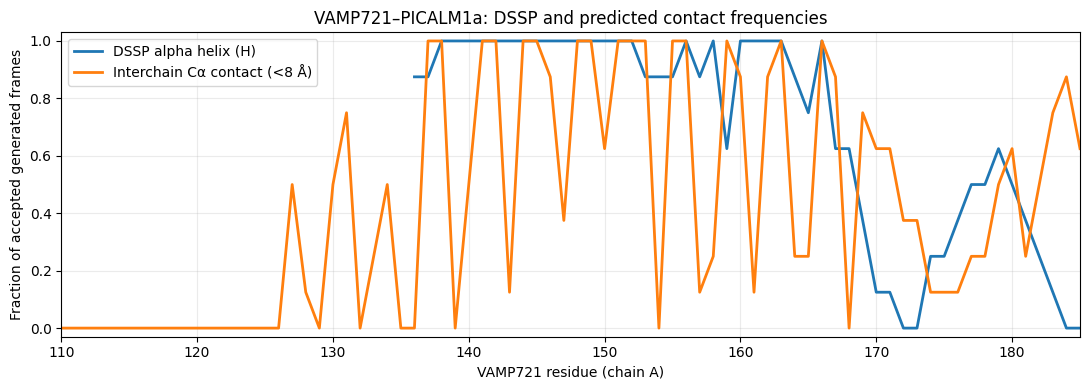

In [ ]:
import matplotlib.pyplot as plt
fig, ax = plt.subplots(figsize=(11,4))
ax.plot(helix_df.vamp_residue, helix_df.fraction_H,
        label="DSSP alpha helix (H)", lw=2)
ax.plot(interface_A.vamp_residue, interface_A.fraction_has_B_contact,
        label=f"Interchain Cα contact (<{CONTACT_CUTOFF_A:g} Å)", lw=2)
ax.set(xlim=(110,len(VAMP_SEQ)),ylim=(-0.03,1.03),
       xlabel="VAMP721 residue (chain A)", ylabel="Fraction of accepted generated frames",
       title="VAMP721–PICALM1a: DSSP and predicted contact frequencies")
ax.legend(); ax.grid(alpha=.25)
fig.tight_layout()
fig.savefig(OUT_DIR/"helix_and_interface.png", dpi=180)
plt.show()

## 13｜可視化②：結合界面の2次元マップ

X軸はVAMP721の残基番号、Y軸は**PICALM1a全長配列上の残基番号**です。色の濃さは、幾何品質合格フレームでの接触頻度を示します。

**演習**：もしB側の接触領域が多くの場所に分散するなら、考えられる原因は何か？ 非特異的な衝突、系のサイズ、界面予測の不確実性も候補として考えてください。

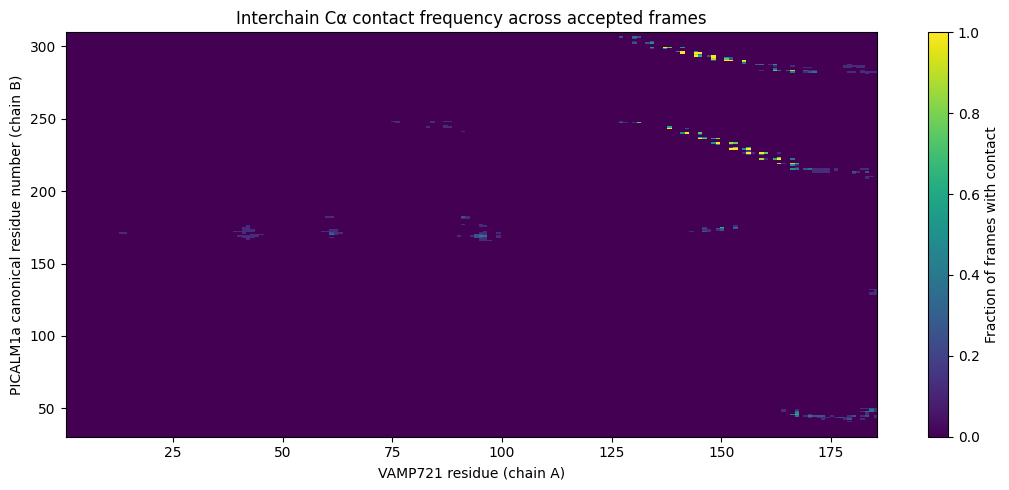

In [ ]:
fig, ax = plt.subplots(figsize=(11,5))
im = ax.imshow(contact_frequency.T, origin="lower", aspect="auto", interpolation="nearest",
               extent=[.5,len(VAMP_SEQ)+.5,PICALM_START-.5,PICALM_END+.5],
               vmin=0,vmax=1,cmap="viridis")
ax.set(xlabel="VAMP721 residue (chain A)",
       ylabel="PICALM1a canonical residue number (chain B)",
       title="Interchain Cα contact frequency across accepted frames")
fig.colorbar(im,ax=ax,label="Fraction of frames with contact")
fig.tight_layout()
fig.savefig(OUT_DIR/"interchain_contact_map.png",dpi=180)
plt.show()

## 14｜Longin–SNARE間接触の変化を数える

従来のOpen/Closed探索ではLonginとSNAREがどの程度近いかを評価してきました。ここでは**Longinコア1–110**と**SNARE評価領域136–185**のCαペアに限定して8 Å未満を数えます。境界が隣接する残基同士の当然の接触を避けるためです。

補助指標として、VAMP721鎖だけのRg（MDTrajの幾何・質量情報による値）も算出します。**複合体全体のRgや実験SAXSのRgと混同しない**こと。

これらは機能的なOpen/Closedを確定する指標ではありません。PICALM認識面の露出や独立実験との照合が必要です。

In [ ]:
longin_ca = [a.index for a in A_ca if 1 <= a.residue.resSeq <= 110]
snare_ca = [a.index for a in A_ca if 136 <= a.residue.resSeq <= 185]
pairs_intra = np.array([(a,b) for a in longin_ca for b in snare_ca],dtype=int)
dist_intra_nm = md.compute_distances(accepted,pairs_intra)
longin_snare_n_pairs = (dist_intra_nm < CONTACT_CUTOFF_A/10).sum(axis=1)

A_atom_indices = [a.index for a in accepted.topology.atoms if a.residue.chain.index==0]
only_vamp = accepted.atom_slice(A_atom_indices)
vamp_rg_nm = md.compute_rg(only_vamp)

per_frame = pd.DataFrame({
    "accepted_frame_0based": np.arange(accepted.n_frames),
    "original_frame_0based": original_frame_ids,
    "vamp136_185_fraction_H": helix_fraction,
    "longest_contiguous_H_residues": longest_H,
    "interchain_CA_pairs_lt_cutoff": interchain_n_pairs,
    "vamp_residues_with_B_contact": interchain_n_A_residues,
    "picalm_residues_with_A_contact": interchain_n_B_residues,
    "longin1_110_snare136_185_CA_pairs_lt_cutoff": longin_snare_n_pairs,
    "vamp_only_rg_A": vamp_rg_nm*10,
})
per_frame.to_csv(OUT_DIR/"complex_metrics_by_accepted_frame.csv",index=False)
display(per_frame)
print("H mean:",f"{helix_fraction.mean():.1%}"," / VAMP-only Rg mean (Å):",round(float((vamp_rg_nm*10).mean()),2))

,accepted_frame_0based,original_frame_0based,vamp136_185_fraction_H,longest_contiguous_H_residues,interchain_CA_pairs_lt_cutoff,vamp_residues_with_B_contact,picalm_residues_with_A_contact,longin1_110_snare136_185_CA_pairs_lt_cutoff,vamp_only_rg_A
0,0,0,0.64,23,84,41,44,0,26.241413
1,1,1,0.82,33,104,42,47,9,25.120546
2,2,2,0.70,21,103,40,49,0,24.055531
3,3,3,0.66,23,92,39,42,2,25.630599
4,4,4,0.78,29,81,36,41,0,26.066595
5,5,5,0.62,31,110,42,49,0,25.574223
6,6,6,0.76,23,81,33,39,0,29.060619
7,7,7,0.64,15,80,34,39,1,28.269867


H mean: 70.2%  / VAMP-only Rg mean (Å): 26.25


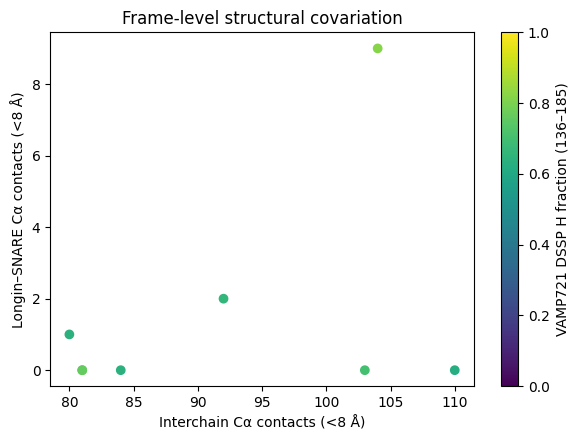

構造群における相関を示すのみ。結合順序・因果関係・遷移速度は示さない。


In [ ]:
# 散布図：鎖間接触とLongin–SNARE接触を同時に観察
fig,ax=plt.subplots(figsize=(6,4.5))
sc=ax.scatter(per_frame.interchain_CA_pairs_lt_cutoff,
              per_frame.longin1_110_snare136_185_CA_pairs_lt_cutoff,
              c=per_frame.vamp136_185_fraction_H,cmap="viridis",vmin=0,vmax=1)
ax.set(xlabel=f"Interchain Cα contacts (<{CONTACT_CUTOFF_A:g} Å)",
       ylabel=f"Longin–SNARE Cα contacts (<{CONTACT_CUTOFF_A:g} Å)",
       title="Frame-level structural covariation")
fig.colorbar(sc,ax=ax,label="VAMP721 DSSP H fraction (136–185)")
fig.tight_layout(); fig.savefig(OUT_DIR/"inter_vs_intra_contacts.png",dpi=180)
plt.show()
print("構造群における相関を示すのみ。結合順序・因果関係・遷移速度は示さない。")

## 15｜任意の発展解析：界面埋没によるSASA低下

SASA（solvent-accessible surface area）は、溶媒分子が接近できる表面積です。**同一座標のVAMP721鎖Aを複合体から単独で取り出したときのSASA**と、複合体中でのA鎖のSASAを比較すると、B鎖が近傍にあることによる埋没の程度を概算できます。

これは**実験的な結合自由エネルギーではありません**。計算負荷を抑えるためデフォルトはOFFです。ONにした場合、単位はnm²で、DSSPと独立な座標由来の指標ですが独立実験証拠ではありません。

In [ ]:
if RUN_OPTIONAL_SASA:
    sasa_complex_nm2 = md.shrake_rupley(accepted, mode="residue", n_sphere_points=100)
    sasa_A_only_nm2 = md.shrake_rupley(only_vamp, mode="residue", n_sphere_points=100)
    sasa_A_complex_nm2 = sasa_complex_nm2[:,[r.index for r in chain_A_residues]]
    assert sasa_A_only_nm2.shape == sasa_A_complex_nm2.shape
    burial_A_nm2 = (sasa_A_only_nm2 - sasa_A_complex_nm2).clip(min=0)
    burial_df = pd.DataFrame({
        "vamp_residue": np.arange(1,len(VAMP_SEQ)+1),
        "average_buried_SASA_nm2": burial_A_nm2.mean(axis=0),
    })
    burial_df.to_csv(OUT_DIR/"vamp721_buried_sasa_by_residue.csv",index=False)
    display(burial_df.sort_values("average_buried_SASA_nm2",ascending=False).head(10))
else:
    print("SASAは未実行です。計算するなら設定セルのRUN_OPTIONAL_SASA=True、RUN_TAGを新しい値にして最初から再実行してください。")

SASAは未実行です。計算するなら設定セルのRUN_OPTIONAL_SASA=True、RUN_TAGを新しい値にして最初から再実行してください。


## 16｜既存のVAMP721単独結果と比較するときのルール

研究ノートで確認されている**単独VAMP721 1–185 / equilibrium100 / seed42のDSSP H率は9.1%**です。これは*過去のAI出力*であり、今回の新規計算から得た値ではありません。

**厳密な比較**を目指す場合は以下の条件を揃えてください。
- A鎖に同じVAMP721 1–185配列を使う。
- 同じBioEmu-2のバージョン、モデル重み、MSA取得条件、`mode="equilibrium"`を使う。
- それぞれの品質合格率、残基対応、標本数、シードを報告する。
- 単独と複合体でPICALM1aの有無以外の差を可能な限り抑える。

**今回8構造の平均と既存100構造の平均を直接比較して因果効果と断定しないこと**。分布の安定性を検証するには複数シード・より大きな構造プール・構築体依存性の評価が必要です。

下のセルは、**両条件が揃う場合にのみ**既存9.1%との参考比較を出力します。

In [ ]:
SOLO_EQUIL_H_FRACTION_PRIOR = 0.091   # 既存研究ノート: 100構造のDSSP H率
if VAMP_CONSTRUCT == "WT_1_185" and MODE == "equilibrium":
    print("以前の単独VAMP721 equilibrium100 (DSSP H, 136–185):",f"{SOLO_EQUIL_H_FRACTION_PRIOR:.1%}")
    print("今回の複合体 accepted frames:", accepted.n_frames)
    print("今回の複合体の同領域H率:", f"{helix_fraction.mean():.1%}")
    print("差（今回－既存）:", f"{helix_fraction.mean()-SOLO_EQUIL_H_FRACTION_PRIOR:+.1%}")
    print("※ 参考差。異なる標本数・品質選択・実行条件を含み、結合効果の推定値ではありません。")
else:
    print("既存の単独equilibrium100と配列長/モードが異なるため、比較を自動表示しません。")

以前の単独VAMP721 equilibrium100 (DSSP H, 136–185): 9.1%
今回の複合体 accepted frames: 8
今回の複合体の同領域H率: 70.2%
差（今回－既存）: +61.1%
※ 参考差。異なる標本数・品質選択・実行条件を含み、結合効果の推定値ではありません。


## 17｜結果の解釈を記録する

得られた構造を次の順番で吟味してください。

1. **入力と品質**：配列・構築体・MSA・モデルモードが記録され、幾何チェックに合格しているか。
2. **界面の妥当性**：VAMP721のSNARE側に接触しているか。PICALM1a側の界面は複数フレームで安定しているか。AF3や実験で提案された界面と対応するか。
3. **局所構造**：接触領域にDSSP Hが形成されているか。構造数とシードを増やしても再現するか。
4. **Open/Closed関連**：Longin–SNAREの近接がどう変わるか。ただし接触数だけで機能的配座は確定しない。
5. **次の独立検証**：CD、NMR、FRET、SPR、HS-AFM、複合体SAXSなどで何を測ると仮説を判別できるか。

**否定的な結果も重要**：複合体が生成されない、界面が不安定、H率が変わらない場合でも、モデル能力、コンストラクト、MSA、実際の結合条件を切り分ける材料になります。

**記入欄（実行後に編集）**：
- 観察（数値・図・フレーム番号）：
- 解釈（AI予測に限定）：
- 代替説明：
- 必要な実験と次のラン：

## 18｜再現性メタデータとZIPを保存

再現に必要な**配列・切り出し領域・モード・シード・サンプラー設定・モデル版・MSA行数・元フレーム番号・接触閾値**を保存します。

- `samples.xtc` + `topology.cif`：生成した**全構造**（不合格も含む）
- `physicality.json` / `quality_by_original_frame.csv`：フレームごとの品質
- `accepted_only/`：品質合格構造だけの別コピー
- `complex_metrics_by_accepted_frame.csv`：解析指標と**元フレーム番号**
- `vamp721_dssp_136_185_by_residue.csv`、`vamp721_picalm_contact_frequency_*.csv`、2D接触マップ：可視化・比較用
- `experiment_metadata.json`：実験設定と注意事項

中断復旧用の`partial/`はZIPには含めません。ZIPには生成構造が含まれるため、大きくなる場合があります。

In [ ]:
import json, zipfile, datetime, platform, subprocess

def safe_git_commit(repo_path):
    repo_path = Path(repo_path)
    if not (repo_path/".git").exists():
        return None
    p = subprocess.run(["git","-C",str(repo_path),"rev-parse","HEAD"],capture_output=True,text=True)
    return p.stdout.strip() if p.returncode==0 else None

metadata = {
    "study": "VAMP721-PICALM1a BioEmu-2 complex ensemble exploration",
    "generated_utc": datetime.datetime.now(datetime.timezone.utc).isoformat(),
    "vamp_construct": VAMP_CONSTRUCT,
    "vamp_sequence": VAMP_SEQ,
    "vamp_length": len(VAMP_SEQ),
    "picalm_construct": PICALM_CONSTRUCT,
    "picalm_sequence": PICALM_SEQ,
    "picalm_full_reference_sequence": PICALM1A_FULL_571,
    "picalm_canonical_residues_included": [PICALM_START,PICALM_END],
    "chain_A": "VAMP721", "chain_B": "PICALM1a",
    "mode": MODE,
    "sampling_mode_settings_reference": "equilibrium: step_scale 1.0; structure: step_scale 1.5 (official defaults)",
    "sampling_preset": "edm (EmuSession.sample default)",
    "contacts_conditioned": False,
    "requested_samples": N_SAMPLES,
    "generated_samples": samples.n_frames,
    "quality_mode": "high_quality",
    "quality_checks_ran": bool(quality.checked),
    "quality_passed": int(passed.sum()),
    "accepted_original_frame_indices_0based": original_frame_ids.tolist(),
    "seed": RANDOM_SEED, "batch_size": BATCH_SIZE,
    "sequence_sha256_prefix": seq_hash,
    "MSA": {"explicitly_loaded": bool(msa is not None), "total_rows_if_available": msa_num_rows,
            "paired_MSA_depth": "not_measured"},
    "cutoff_interchain_angstrom": CONTACT_CUTOFF_A,
    "intra_contact_regions": {"longin_core":[1,110],"snare":[136,185]},
    "DSSP_definition": "H only, residue 136-185 (50 aa)",
    "bioemu2_package_version": importlib.metadata.version("bioemu2"),
    "installed_repo_git_commit_if_available": safe_git_commit("/content/bioemu2_source"),
    "checkpoint": "bioemu2-preview (explicitly requested from load_model)",
    "torch_version": torch.__version__,
    "python_version": sys.version.split()[0],
    "gpu": torch.cuda.get_device_name(0),
    "protein_SAXS_measurement_complex": False,
    "experimental_thermodynamic_populations_inferred": False,
    "notes": ["Frames are independently sampled predictions, not a time trajectory.",
              "Physicality pass is a geometry screen, not a binding validation.",
              "PICALM1a 31-309 is an exploratory fragment; binding competence not established.",
              "SAXS construct identity not verified."],
}
(OUT_DIR/"experiment_metadata.json").write_text(json.dumps(metadata,indent=2,ensure_ascii=False),encoding="utf-8")
zip_path = OUT_ROOT / f"{RUN_NAME}_results.zip"
with zipfile.ZipFile(zip_path,"w",zipfile.ZIP_DEFLATED,compresslevel=6) as z:
    for f in sorted(OUT_DIR.rglob("*")):
        if not f.is_file(): continue
        if "partial" in f.relative_to(OUT_DIR).parts: continue
        z.write(f,arcname=f"{RUN_NAME}/{f.relative_to(OUT_DIR)}")
print("ZIP:",zip_path,"Size MiB:",round(zip_path.stat().st_size/1024**2,2))
print("Results directory:",OUT_DIR)
if AUTO_DOWNLOAD_ZIP:
    from google.colab import files
    files.download(str(zip_path))

ZIP: /content/vamp721_picalm_bioemu2_v2/VAMP185_WT_1_185_PICALM_ANTH_31_309_equilibrium_N8_seed42_b1_2c112589ed_trial01_results.zip Size MiB: 0.71
Results directory: /content/vamp721_picalm_bioemu2_v2/VAMP185_WT_1_185_PICALM_ANTH_31_309_equilibrium_N8_seed42_b1_2c112589ed_trial01


## 19｜次の研究段階と、完了時のチェックリスト

- [ ] Equilibrium：VAMP721 1–185 + PICALM1a 31–309で**合格構造が得られた**。
- [ ] 解析表に**元のフレーム番号**と**PICALM1aの天然配列上の残基番号**がある。
- [ ] 3Dと接触マップで、結合候補界面が繰り返し現れるか確認した。
- [ ] DSSPの`H`率、鎖間接触、Longin–SNARE接触の分布を整理した。
- [ ] **複数シード**で結果が再現するか確認した。
- [ ] 単独と複合体を同じモード・同じ配列・できるだけ同じ実行条件で比較した。
- [ ] 194 aaや全長PICALM1aの追加計算を、別の科学的問いとして位置付けた。

**次の提案**：このノートブックで初回8構造が完走・品質合格したら、同条件で50–100構造へ拡張し、独立シードでの再現性を評価します。相互作用の有無・結合速度・熱力学的平衡や、SAXSへの適合は**別の研究段階**で検証します。

**主要資料**：[BioEmu-2公式Sampling](https://github.com/microsoft/bioemu2/blob/main/docs/sampling.md) ／ [System](https://github.com/microsoft/bioemu2/blob/main/docs/system.md) ／ [MSA](https://github.com/microsoft/bioemu2/blob/main/docs/msa.md) ／ Fujimoto et al. *PNAS* (2020), PMID: [32968023](https://pubmed.ncbi.nlm.nih.gov/32968023/)。

In [ ]:

import io
import zipfile
from pathlib import Path

import numpy as np
import mdtraj as md
from scipy.spatial import cKDTree
from google.colab import files

# 1. ZIPを読み込む
uploaded = files.upload()
zip_name = next(iter(uploaded))

out = Path("/content/interface_validation")
out.mkdir(exist_ok=True)

with zipfile.ZipFile(io.BytesIO(uploaded[zip_name])) as z:
    for filename in ("samples.xtc", "topology.cif"):
        member = next(
            n for n in z.namelist()
            if n.endswith("accepted_only/" + filename)
        )
        (out / filename).write_bytes(z.read(member))

traj = md.load(
    str(out / "samples.xtc"),
    top=str(out / "topology.cif")
)

print("Frames:", traj.n_frames)
print("Atoms:", traj.n_atoms)

# 2. 鎖ごとの原子を取得
atoms = list(traj.topology.atoms)

A = np.array([
    a.index for a in atoms
    if a.residue.chain.index == 0
])
B = np.array([
    a.index for a in atoms
    if a.residue.chain.index == 1
])

# 3. SASAと埋没表面積を計算
def sasa_total(t):
    return md.shrake_rupley(
        t, n_sphere_points=200
    ).sum(axis=1)

s_complex = sasa_total(traj)
s_A = sasa_total(traj.atom_slice(A))
s_B = sasa_total(traj.atom_slice(B))

# nm² → Å²、片側換算
bsa = (s_A + s_B - s_complex) * 100 / 2

print("\nInterface area (Å²):")
print(np.round(bsa, 1))
print("Mean:", round(float(bsa.mean()), 1))

# 4. 異鎖間の極端に近い重原子ペアを検出
Ah = np.array([
    i for i in A if atoms[i].element.symbol != "H"
])
Bh = np.array([
    i for i in B if atoms[i].element.symbol != "H"
])

for frame in range(traj.n_frames):
    xyz_A = traj.xyz[frame, Ah] * 10
    xyz_B = traj.xyz[frame, Bh] * 10

    near = cKDTree(xyz_A).sparse_distance_matrix(
        cKDTree(xyz_B),
        max_distance=2.2,
        output_type="dict"
    )

    for (i, j), distance in near.items():
        atom_a = atoms[Ah[i]]
        atom_b = atoms[Bh[j]]

        print(
            f"Frame {frame}: "
            f"A{atom_a.residue.resSeq}.{atom_a.name} - "
            f"B{atom_b.residue.resSeq + 30}.{atom_b.name}: "
            f"{distance:.2f} Å"
        )


Saving VAMP185_WT_1_185_PICALM_ANTH_31_309_equilibrium_N8_seed42_b1_2c112589ed_trial01_results.zip to VAMP185_WT_1_185_PICALM_ANTH_31_309_equilibrium_N8_seed42_b1_2c112589ed_trial01_results.zip
Frames: 8
Atoms: 3736

Interface area (Å²):
[2525.9 2234.6 2565.5 2257.1 2374.9 2566.1 2352.7 2413.4]
Mean: 2411.3
Frame 0: A179.O - B282.OE1: 2.02 Å
Frame 7: A176.CE1 - B48.CE: 1.62 Å


In [ ]:
traj[0].save_pdb("/content/frame_00.pdb")
traj[7].save_pdb("/content/frame_07.pdb")